# Modelling an Infected Cohort (Python)

**Training module 1: Introduction to infectious disease modelling**

In this activity, you will code a simple compartmental model and use it to answer a research question. The model follows a cohort of people who are currently infected and tracks their movement into the recovered compartment.

We will use Python packages commonly used for scientific computing:
- **NumPy** for numerical operations,
- **SciPy** to solve the differential equations,
- **pandas** to organize model output, and
- **Matplotlib** to plot the results.

If you are using Google Colab or JupyterLab, run the code cells in order.

## 1. Model description

Suppose we start with a cohort of \(10^6\) infected people. Individuals recover at rate \(\gamma\), and recovered individuals do not return to the infected compartment in this simple model.

We track two compartments:

- \(I(t)\): number of infected people at time \(t\)
- \(R(t)\): number of recovered people at time \(t\)

The model is described by the ordinary differential equations

\[
\frac{dI}{dt} = -\gamma I, \qquad
\frac{dR}{dt} = \gamma I.
\]

The average duration of infection is 10 days, so the recovery rate is \(\gamma = 1/10 = 0.1\) per day. We will follow the cohort for 4 weeks (28 days).

**Assumption:** this is a closed cohort with no new infections, births, deaths, or loss of immunity. The total \(I(t)+R(t)\) therefore remains constant.

## 2. Import the required packages

Run this cell as it is. If SciPy or another package is missing from your local Python environment, install it first (for example, with `pip install numpy scipy pandas matplotlib`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Display plots inside the notebook
%matplotlib inline

## 3. Define the initial conditions and parameters

We begin with 1,000,000 infected people and no recovered people. The average infectious period is 10 days, and the follow-up period is 28 days.

**Think about:** What do the initial state dictionary and parameter value represent? What are the units of the recovery rate?

In [6]:
initial_number_infected = 1_000_000
initial_number_recovered = 0

average_infectious_period = 10  # days
recovery_rate = 1 / average_infectious_period  # gamma, per day
follow_up_duration = 28  # days

# State variables at time zero
initial_state_values = {
    "I": initial_number_infected,
    "R": initial_number_recovered,
}

# Model parameter
gamma = recovery_rate

# Times (days) at which we want model results
#times = np.arange(0, follow_up_duration + 1, 1)
times = np.linspace(0, follow_up_duration, 29)

print("Initial state values:", initial_state_values)
print("Recovery rate (per day):", gamma)
print("First and last timepoints:", times[0], "and", times[-1], "days")

Initial state values: {'I': 1000000, 'R': 0}
Recovery rate (per day): 0.1
First and last timepoints: 0.0 and 28.0 days


## 4. Specify the model

The model function receives the current time, the current state values, and the model parameter. It returns the rates of change of the infected and recovered compartments.

**Check the signs:** infected people leave \(I\), so \(dI/dt\) is negative. Those same people enter \(R\), so \(dR/dt\) is positive.

In [8]:
def cohort_model(t, state, gamma):
    """Return the derivatives dI/dt and dR/dt for the infected-cohort model.

    Parameters
    ----------
    t : float
        Time (days). Included because ODE solvers expect the function to accept it.
    state : sequence
        Current values [I, R].
    gamma : float
        Recovery rate (per day).

    Returns
    -------
    list
        Derivatives [dI/dt, dR/dt].
    """
    I, R = state

    dI_dt = -gamma * I
    dR_dt = gamma * I

    return [dI_dt, dR_dt]

## 5. Solve the differential equations

We use `scipy.integrate.solve_ivp`, which numerically solves the system of ordinary differential equations. The `t_eval` argument tells the solver which timepoints to return.

The solution is converted to a pandas DataFrame so that it is easy to inspect, summarize, and plot.

In [9]:
solution = solve_ivp(
    fun=lambda t, y: cohort_model(t, y, gamma),
    t_span=(times[0], times[-1]),
    y0=[initial_state_values["I"], initial_state_values["R"]],
    t_eval=times,
    method="RK45",
    rtol=1e-8,
    atol=1e-8,
)

if not solution.success:
    raise RuntimeError(solution.message)

output = pd.DataFrame({
    "time": solution.t,
    "I": solution.y[0],
    "R": solution.y[1],
})

output.head()

,time,I,R
0,0.0,1000000.000000,0.000000
1,1.0,904837.418031,95162.581969
2,2.0,818730.752612,181269.247388
3,3.0,740818.220583,259181.779417
4,4.0,670320.046158,329679.953842


The output contains one row per requested timepoint:
- `time`: time in days,
- `I`: number of infected people,
- `R`: number of recovered people.

Display the complete output if you wish to inspect all 29 timepoints.

In [ ]:
output

,time,I,R
0,0,1000000.000000,0.000000
1,1,904837.418031,95162.581969
2,2,818730.752612,181269.247388
3,3,740818.220583,259181.779417
4,4,670320.046158,329679.953842
5,5,606530.659255,393469.340745
6,6,548811.635267,451188.364733
7,7,496585.302979,503414.697021
8,8,449328.963505,550671.036495
9,9,406569.659372,593430.340628


## 6. Answer the research question

**Question:** How many people have recovered after 4 weeks? What proportion of the total cohort does this represent?

Use the final row of the model output rather than reading the value from the table by eye.

In [10]:
final_infected = output.loc[output.index[-1], "I"]
final_recovered = output.loc[output.index[-1], "R"]
total_population = initial_number_infected + initial_number_recovered
proportion_recovered = final_recovered / total_population

print(f"Recovered after {follow_up_duration} days: {final_recovered:,.0f}")
print(f"Proportion recovered: {proportion_recovered:.4f} ({proportion_recovered:.1%})")
print(f"Still infected after {follow_up_duration} days: {final_infected:,.0f}")
print(f"Total I + R at the end: {final_infected + final_recovered:,.0f}")

Recovered after 28 days: 939,190
Proportion recovered: 0.9392 (93.9%)
Still infected after 28 days: 60,810
Total I + R at the end: 1,000,000


## 7. Plot the model output

Plot the number of infected and recovered people over time. The two curves should move in opposite directions: the infected population decreases while the recovered population increases.

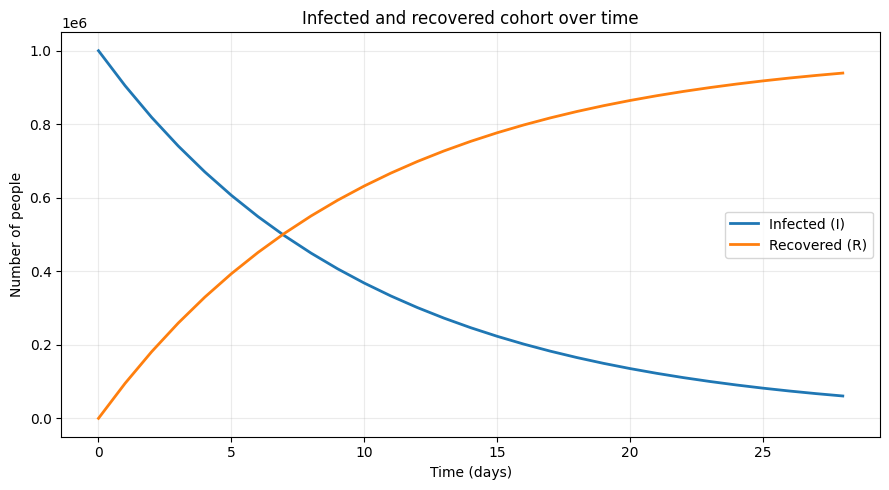

In [11]:
plt.figure(figsize=(9, 5))
plt.plot(output["time"], output["I"], label="Infected (I)", linewidth=2)
plt.plot(output["time"], output["R"], label="Recovered (R)", linewidth=2)
plt.xlabel("Time (days)")
plt.ylabel("Number of people")
plt.title("Infected and recovered cohort over time")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Question:** Based on the plot, at approximately what timepoint are infected and recovered individuals equal in number?

Hint: in this model, the two groups are equal when each contains half of the initial cohort.

In [ ]:
# Find the output timepoint at which |I - R| is smallest
equal_index = (output["I"] - output["R"]).abs().idxmin()
print(f"Closest evaluated timepoint: day {output.loc[equal_index, 'time']:.0f}")
print(f"Infected: {output.loc[equal_index, 'I']:,.0f}")
print(f"Recovered: {output.loc[equal_index, 'R']:,.0f}")

## 8. Explore different recovery rates

Now investigate how the recovery rate affects the model. The recovery rate is the reciprocal of the average infectious period:

\[
\gamma = rac{1}{	ext{average infectious period}}.
\]

Try these two scenarios:
- **Scenario A:** average infectious period = 2 days
- **Scenario B:** average infectious period = 20 days

For each scenario, calculate the recovery rate, solve the model again, and plot the results. Notice that the initial conditions and timepoints remain unchanged.

In [ ]:
def run_cohort_model(average_infectious_period, times=times):
    """Solve the cohort model for a specified average infectious period (days)."""
    scenario_gamma = 1 / average_infectious_period

    scenario_solution = solve_ivp(
        fun=lambda t, y: cohort_model(t, y, scenario_gamma),
        t_span=(times[0], times[-1]),
        y0=[initial_number_infected, initial_number_recovered],
        t_eval=times,
        method="RK45",
        rtol=1e-8,
        atol=1e-8,
    )

    if not scenario_solution.success:
        raise RuntimeError(scenario_solution.message)

    scenario_output = pd.DataFrame({
        "time": scenario_solution.t,
        "I": scenario_solution.y[0],
        "R": scenario_solution.y[1],
    })
    return scenario_gamma, scenario_output


scenarios = {
    "Average infectious period: 2 days": 2,
    "Average infectious period: 20 days": 20,
}

scenario_results = {}
for label, duration in scenarios.items():
    scenario_gamma, scenario_output = run_cohort_model(duration)
    scenario_results[label] = scenario_output
    recovered_at_end = scenario_output["R"].iloc[-1]
    print(f"{label}: gamma = {scenario_gamma:.3f} per day; "
          f"recovered by day {follow_up_duration} = {recovered_at_end:,.0f}")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)

for ax, (label, scenario_output) in zip(axes, scenario_results.items()):
    ax.plot(scenario_output["time"], scenario_output["I"], label="Infected (I)", linewidth=2)
    ax.plot(scenario_output["time"], scenario_output["R"], label="Recovered (R)", linewidth=2)
    ax.set_title(label)
    ax.set_xlabel("Time (days)")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Number of people")
axes[0].legend()
axes[1].legend()
fig.suptitle("Effect of the average infectious period")
fig.tight_layout()
plt.show()

## 9. Interpretation and discussion

**Questions to discuss:**

1. How does a higher recovery rate affect the speed at which people leave the infected compartment?
2. Why does the 2-day infectious-period scenario recover more quickly than the 20-day scenario?
3. Does the model suggest that everyone has recovered by day 28 in either scenario? Explain what “everyone” means in a continuous deterministic model.
4. What assumptions make this a very simple model of infection?

**Key points:**
- A shorter average infectious period corresponds to a higher recovery rate.
- The model has no new infections, so the infected cohort declines monotonically.
- In a deterministic model, \(I(t)\) approaches zero asymptotically; it generally does not become exactly zero at a finite time.
- Since \(dI/dt + dR/dt = 0\), the total cohort \(I(t)+R(t)\) is conserved.

## 10. Optional extension

The infected equation has an analytical solution:

\[
I(t) = I(0)e^{-\gamma t}, \qquad
R(t) = I(0)\left(1-e^{-\gamma t}
ight) + R(0).
\]

Compare these expressions with the numerical solution from `solve_ivp`. This is a useful check that the numerical model has been implemented correctly.

In [ ]:
# Optional validation against the analytical solution
I_analytical = initial_number_infected * np.exp(-gamma * times)
R_analytical = initial_number_recovered + initial_number_infected * (1 - np.exp(-gamma * times))

print("Maximum absolute difference for I:",
      f"{np.max(np.abs(output['I'].to_numpy() - I_analytical)):,.6f}")
print("Maximum absolute difference for R:",
      f"{np.max(np.abs(output['R'].to_numpy() - R_analytical)):,.6f}")